# Gini prep lab — from scorecard build to IFRS 9 ECL

You're the consultant. A UK lender hands you its unsecured personal-loan book (40,000 loans, originated 2016–2020, monthly performance to Dec 2022) and asks for:

1. a new **application scorecard**, built the way Gini's insights pieces describe (account-data features → tree binning → WoE → MIV selection → transparent logistic, elastic net as challenger), and validated;
2. an **IFRS 9 view**: a forward-looking PD, a SICR threshold set at the point of optimal discrimination, a probability-weighted ECL, and a post-model adjustment if the backtest says you need one.

The data is synthetic, but built so the real traps are in it. Some fields leak. Two are near-duplicates. Something happens to the bureau in mid-2019. Something happens to one segment in 2022. You find them; the checkpoints tell you if you have.

**How to use this**
- Work top to bottom. Each `TODO` cell has a checkpoint after it. ❌ = go and look, not "wrong".
- Each module ends with an **🎤 out-loud question**. Answer it out loud in under a minute. That's the interview.
- Don't open `_answers/` until you're done. `solutions.ipynb` is there when you're stuck for >20 min.
- **If time is short**, the core path is modules 1, 3, 4, 5, 7, 9a, 9c, 9d (~5–6 hours). Modules 2, 6, 8, 9b, 9e deepen it.

| Module | Gini source it mirrors |
|---|---|
| 2 Feature synthesis | *Deep feature synthesis for credit scorecards* |
| 3–5 Binning, WoE, MIV | same (the Revolut pipeline they describe) |
| 6 Elastic net & stability | *Elastic net models for credit risk scorecards* |
| 7 Validation & drift | *TrueVision transition* pieces; SS1/23 |
| 9 SICR, ECL, overlays | *IFRS 9 staging, overlays and judgement*; the two-portfolio IFRS 9 case study |

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import checks

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
D = "data/"
loans = pd.read_csv(D + "loans.csv")
perf  = pd.read_parquet(D + "performance.parquet")
acct  = pd.read_csv(D + "account_history.csv")
macro = pd.read_csv(D + "macro.csv")
perf["m"] = pd.PeriodIndex(perf["month"], freq="M")
gini = lambda y, p: 2 * roc_auc_score(y, p) - 1
print(loans.shape, perf.shape, acct.shape, macro.shape)

(40000, 22) (1186540, 7) (240000, 9) (444, 3)


In [4]:
loans

,loan_id,orig_month,loan_amount,term_months,interest_rate,channel,region,postcode_district,credit_score,util_ratio,revolving_bal_to_limit,num_inquiries_6m,months_since_last_delinq,annual_income,dti,emp_years,homeowner,collections_letters_12m,district_bad_rate,close_month,close_reason,default_month
0,0,2019-01,9700.0,36,0.0851,direct,Midlands,MI118,682,0.4311,0.4198,2,NaN,50800.0,0.0761,2.0,1,0,0.0416,2021-12,matured,NaN
1,1,2017-10,8200.0,60,0.1273,aggregator,Wales,WA149,593,0.7431,0.7109,2,43.0,30800.0,0.2454,4.8,0,0,0.0061,2020-01,written_off,2019-07
2,2,2020-10,9000.0,48,0.1147,direct,South East,SO070,644,0.3417,0.3093,3,48.0,18600.0,0.2052,1.8,0,0,0.0298,NaN,NaN,NaN
3,3,2016-11,11600.0,48,0.0940,direct,South East,SO045,656,0.7054,0.6883,0,NaN,49000.0,0.3217,0.3,1,0,0.0526,2017-01,prepaid,NaN
4,4,2019-05,28200.0,24,0.0896,direct,London,LO124,665,0.2920,0.2732,2,NaN,16000.0,0.2804,2.1,0,1,0.0251,2021-04,matured,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,39995,2020-11,18000.0,36,0.1067,direct,Midlands,MI094,702,0.4264,0.3957,3,NaN,21600.0,0.5119,1.9,0,0,0.0809,NaN,NaN,NaN
39996,39996,2019-03,11500.0,36,0.0907,direct,North West,NO133,669,0.7460,0.7078,1,NaN,30200.0,0.1884,0.2,0,0,0.0056,2022-05,written_off,2021-11
39997,39997,2016-02,5000.0,48,0.0850,broker,Yorkshire,YO016,711,0.2035,0.1851,1,NaN,21300.0,0.2200,7.2,1,1,0.0882,2020-01,matured,NaN
39998,39998,2016-11,14700.0,48,0.0961,direct,Yorkshire,YO115,621,0.7737,0.7755,1,NaN,18100.0,0.1778,16.7,0,1,0.0079,2020-10,matured,NaN


In [5]:
perf[perf.loan_id == 123].head(20)

,loan_id,month,mob,balance,dpd_bucket,bureau_score,m
672629,123,2020-04,1,2731.34,0,742,2020-04
693218,123,2020-05,2,2662.20,0,735,2020-05
713988,123,2020-06,3,2592.58,0,585,2020-06
734826,123,2020-07,4,2522.47,0,594,2020-07
755746,123,2020-08,5,2451.86,0,592,2020-08
776751,123,2020-09,6,2380.77,0,602,2020-09
797807,123,2020-10,7,2309.17,0,582,2020-10
818942,123,2020-11,8,2237.08,0,615,2020-11
840140,123,2020-12,9,2164.48,0,592,2020-12
861383,123,2021-01,10,2091.37,0,595,2021-01


**Data dictionary (short)**

- `loans.csv` — one row per loan. Application fields, plus `close_month / close_reason / default_month` (outcomes — obviously not features).
- `account_history.csv` — 6 monthly current-account summaries per applicant before application (`month_offset` −6…−1).
- `performance.parquet` — loan × month panel: `mob`, `balance`, `dpd_bucket` (0 = up to date, 1 = 30–59, 2 = 60–89, 3 = 90+ = default), `bureau_score` (refreshed monthly, already bridged to one scale).
- `macro.csv` — unemployment history to Dec 2022, then `base / upside / downside` paths to 2032.

Have a poke around before starting: `loans.describe()`, a couple of loans' rows in `perf`, a plot of unemployment.


# Some vintage analysis when openign a new credit book

First we will get a graph of cumulative default rate againt months on book for each vintage

In [6]:
loans["vint_y"] = pd.PeriodIndex(loans["orig_month"], freq="M").year

# first month each loan hit 90+ (dpd_bucket 3), as months-on-book and as a calendar month
fd = (perf[perf["dpd_bucket"] == 3]
      .groupby("loan_id")
      .agg(def_mob=("mob", "min"), def_m=("m", "min")))
L = loans.set_index("loan_id").join(fd)

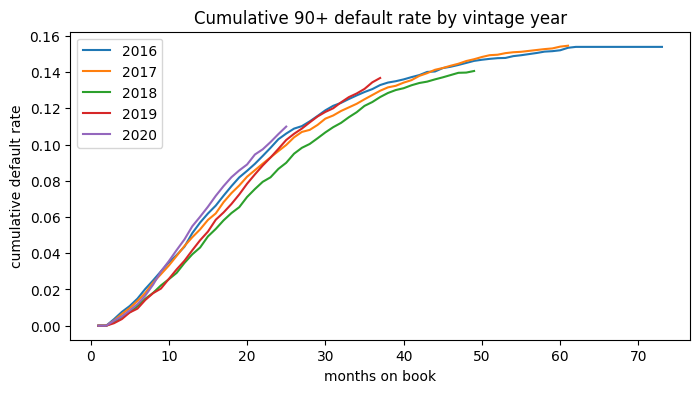

,2016,2017,2018,2019,2020
6,0.0150,0.0137,0.0108,0.0094,0.0119
12,0.0436,0.0440,0.0346,0.0358,0.0476
18,0.0770,0.0732,0.0622,0.0672,0.0820
24,0.1029,0.0964,0.0866,0.0976,0.1058
36,0.1306,0.1273,0.1235,0.1343,NaN


In [7]:
# how many months each loan *could* have been observed for, up to Dec 2022
last = pd.Period("2022-12", "M")
L["obs_mob"] = (last - pd.PeriodIndex(L["orig_month"], freq="M")).map(lambda x: x.n) + 1

curves = {}
for v, g in L.groupby("vint_y"):
    max_k = g["obs_mob"].min()   # stop where the youngest loan in the vintage runs out of data
    curves[v] = pd.Series([(g["def_mob"] <= k).mean() for k in range(1, max_k + 1)],
                          index=range(1, max_k + 1))
cum = pd.DataFrame(curves)

cum.plot(figsize=(8, 4), title="Cumulative 90+ default rate by vintage year")
plt.xlabel("months on book"); plt.ylabel("cumulative default rate"); plt.show()
cum.loc[[6, 12, 18, 24, 36]].round(4)

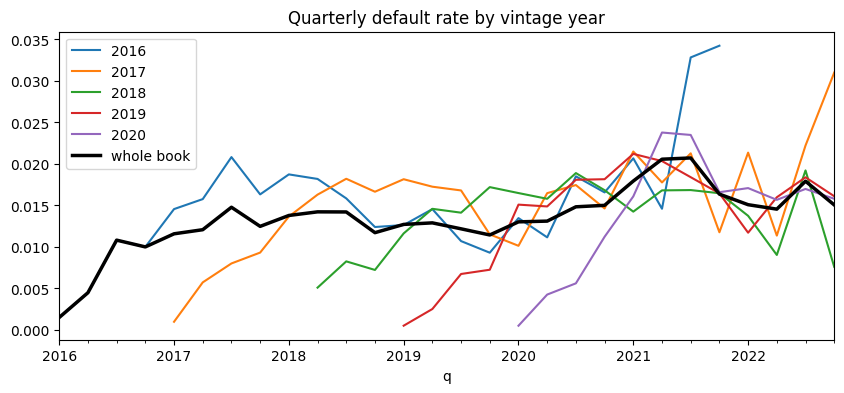

In [8]:
perf["q"] = perf["m"].dt.asfreq("Q")
perf["vy"] = perf["loan_id"].map(L["vint_y"])

# denominator: loans not yet in default during the quarter
at_risk = perf[perf["dpd_bucket"] < 3].groupby(["vy", "q"])["loan_id"].nunique()

# numerator: loans whose first default month falls in that quarter
x = perf.join(fd, on="loan_id")
new_def = x[x["m"] == x["def_m"]].groupby(["vy", "q"]).size()

qrate = (new_def / at_risk).unstack(0)
ax = qrate.plot(figsize=(10, 4), title="Quarterly default rate by vintage year")

overall = new_def.groupby("q").sum() / at_risk.groupby("q").sum()
overall.plot(ax=ax, color="k", lw=2.5, label="whole book")
ax.legend(); plt.show()

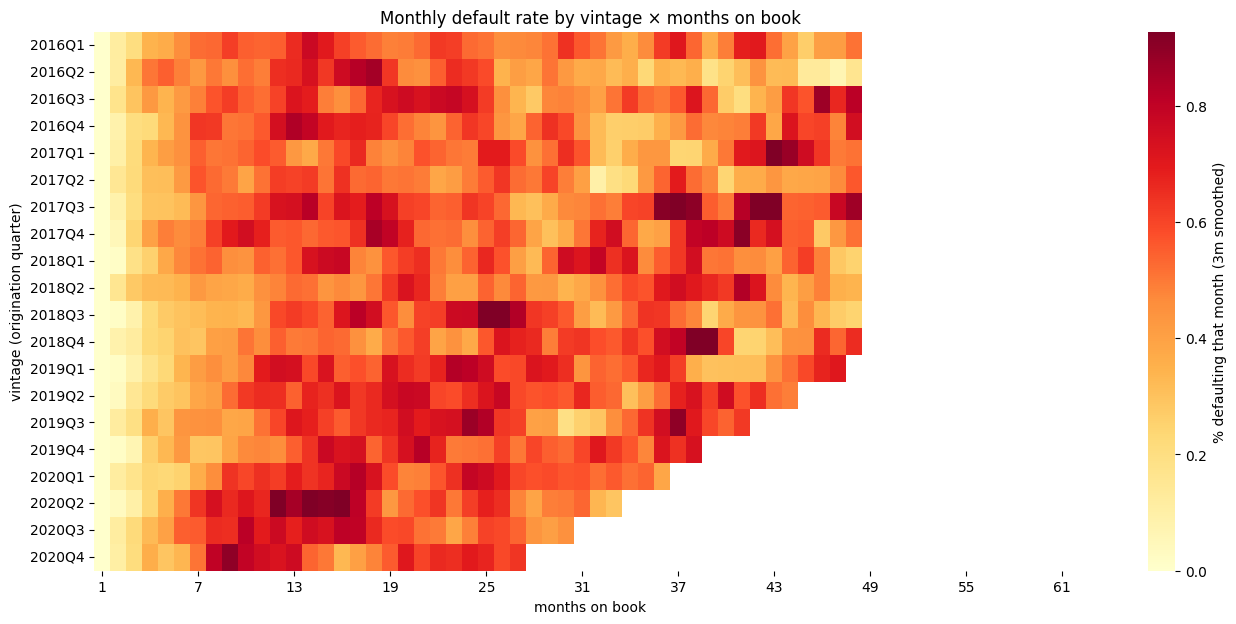

In [9]:
import seaborn as sns

# first default month per loan, and a flag on the month it happens
fd = perf[perf["dpd_bucket"] == 3].groupby("loan_id").agg(def_m=("m", "min"))
x = perf.join(fd, on="loan_id")
x["new_def"] = (x["m"] == x["def_m"]).astype(int)

# at risk = not already in default (keep the month they default in)
x = x[(x["dpd_bucket"] < 3) | (x["new_def"] == 1)]

# vintage quarter per loan
vq = pd.PeriodIndex(loans["orig_month"], freq="M").asfreq("Q").astype(str)
x["vq"] = x["loan_id"].map(pd.Series(vq, index=loans["loan_id"]))

g = x.groupby(["vq", "mob"]).agg(at_risk=("loan_id", "size"), defs=("new_def", "sum"))
at_risk = g["at_risk"].unstack("mob")
defs = g["defs"].unstack("mob")

# 3-month smoothing: pool defaults and at-risk counts over a centred window, then divide
roll = lambda t: t.T.rolling(3, center=True, min_periods=1).sum().T
rate = (roll(defs) / roll(at_risk) * 100).where(at_risk >= 300)   # blank out thin cells

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(rate, cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(rate.values, 99),
            xticklabels=6, ax=ax, cbar_kws={"label": "% defaulting that month (3m smoothed)"})
ax.set_xlabel("months on book"); ax.set_ylabel("vintage (origination quarter)")
ax.set_title("Monthly default rate by vintage × months on book"); plt.show()

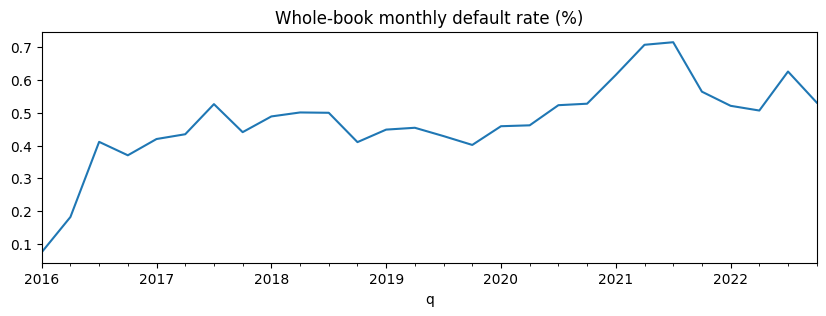

In [10]:
x["q"] = x["m"].dt.asfreq("Q")
book = x.groupby("q").agg(at_risk=("loan_id", "size"), defs=("new_def", "sum"))
(book["defs"] / book["at_risk"] * 100).plot(figsize=(10, 3), title="Whole-book monthly default rate (%)"); plt.show()

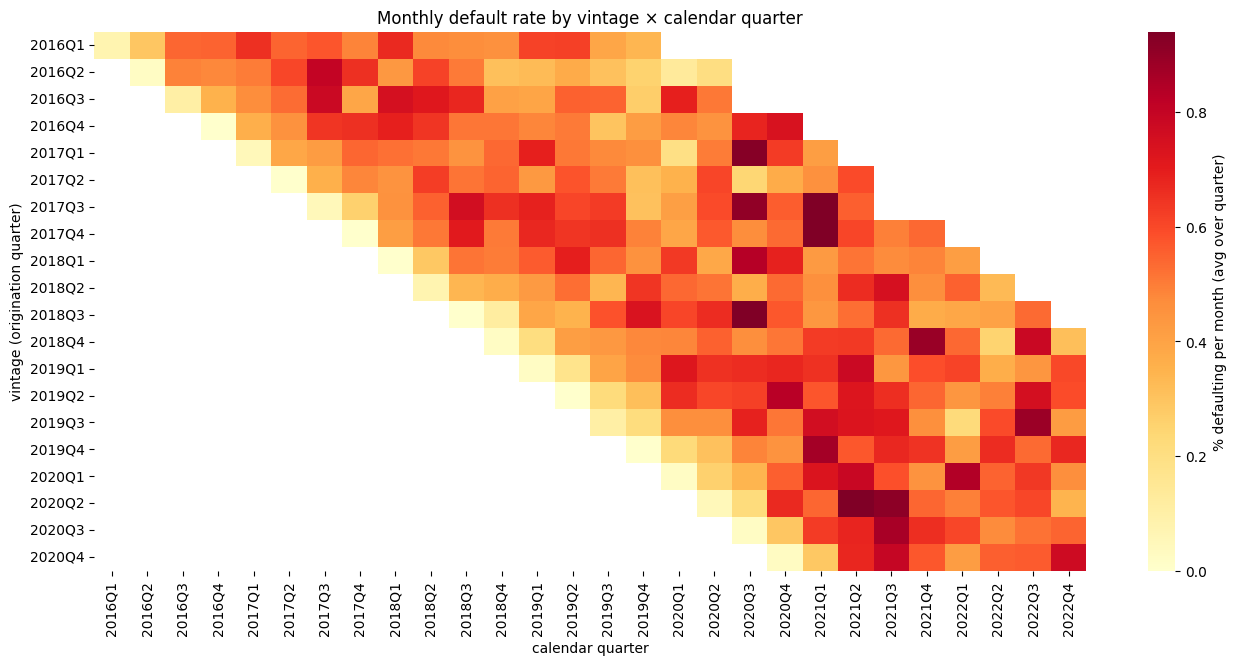

In [11]:
x["q"] = x["m"].dt.asfreq("Q").astype(str)

g = x.groupby(["vq", "q"]).agg(loan_months=("loan_id", "size"), defs=("new_def", "sum"))
rate_cal = (g["defs"] / g["loan_months"] * 100).where(g["loan_months"] >= 900).unstack("q")

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(rate_cal, cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(rate_cal.values, 99), ax=ax,
            cbar_kws={"label": "% defaulting per month (avg over quarter)"})
ax.set_xlabel("calendar quarter"); ax.set_ylabel("vintage (origination quarter)")
ax.set_title("Monthly default rate by vintage × calendar quarter"); plt.show()

---
## Module 1 · Target and sample

**Bad** = reached 90+ DPD (`dpd_bucket == 3`) within the first 12 months on book. Loans that prepay before month 12 without defaulting count as good (note in your head that some shops treat them as *indeterminate* — know why).

**Split by time, not at random**: development = vintages 2016-01 to 2018-12; out-of-time (OOT) = 2019-01 to 2020-12.

Why time? Because the question a validator asks is "does it work on loans it hasn't seen, *written later*?" A random split can't answer that.

In [12]:
# worst delinquency status each loan reached in its first 12 months on book
first12 = perf[perf["mob"] <= 12].groupby("loan_id")["dpd_bucket"].max()

# bad = hit 90+ (bucket 3) in that window; loans with no rows map to NaN, so fill with 0
loans["bad"] = (loans["loan_id"].map(first12).fillna(0) >= 3).astype(int)

loans["vintage"] = pd.PeriodIndex(loans["orig_month"], freq="M")

# split by time: dev = written up to end-2018, OOT = written 2019 onwards
dev = loans[loans["vintage"] <= pd.Period("2018-12", "M")].copy()
oot = loans[loans["vintage"] >  pd.Period("2018-12", "M")].copy()

print(len(dev), round(dev["bad"].mean(), 4), len(oot), round(oot["bad"].mean(), 4))

24070 0.0408 15930 0.0417


In [13]:
perf

,loan_id,month,mob,balance,dpd_bucket,bureau_score,m,q,vy
0,113,2016-01,1,7218.54,0,712,2016-01,2016Q1,2016
1,117,2016-01,1,6835.20,0,662,2016-01,2016Q1,2016
2,136,2016-01,1,14055.82,0,611,2016-01,2016Q1,2016
3,149,2016-01,1,18833.83,0,678,2016-01,2016Q1,2016
4,178,2016-01,1,10926.48,0,665,2016-01,2016Q1,2016
...,...,...,...,...,...,...,...,...,...
1186535,39978,2022-12,27,5424.38,0,618,2022-12,2022Q4,2020
1186536,39979,2022-12,32,4899.77,0,661,2022-12,2022Q4,2020
1186537,39986,2022-12,31,4863.02,0,734,2022-12,2022Q4,2020
1186538,39988,2022-12,34,746.20,0,716,2022-12,2022Q4,2020


In [14]:
perf["dpd_bucket"].value_counts().sort_index()

dpd_bucket
0    1132814
1      12455
2       7266
3      34005
Name: count, dtype: int64

In [15]:
checks.m1(dev, oot)

Checkpoint 1 · target & sample
  ✅ 24,070 dev / 15,930 OOT loans
  ✅ dev bad rate = 0.0408
  ✅ OOT bad rate = 0.0417


True

🎤 *"Your bad rate by vintage year moves around. Is that the borrowers or the economy — and why does it matter for a scorecard vs an IFRS 9 PD?"*

---
## Module 2 · Features from account history (deep feature synthesis, by hand)

DFS stacks three operations over related tables: *entity* features (within one row), *direct* features (pulled across a join), *relational* features (aggregations over many rows). Here the relation is applicant → 6 monthly account rows.

**Task**: build a feature table `feats` (index = `loan_id`) from `acct`. For each numeric column generate at least: mean, max, min, last month (`month_offset == -1`), non-zero month count, and a **trend** (mean of last 3 months − mean of first 3). Add one ratio of your own (e.g. outflow / inflow). Drop constant columns.

Optional: `pip install featuretools` and do it properly with `ft.dfs(..., max_depth=2)` — then notice how fast the candidate count explodes, which is exactly the article's point.

In [30]:
num_cols = ["total_inflow", "total_outflow", "avg_balance", "overdraft_days",
            "returned_dd_count", "gambling_spend", "salary_credit"]

g     = acct.groupby("loan_id")
last  = acct[acct["month_offset"] == -1].set_index("loan_id")       # month before application
late  = acct[acct["month_offset"] >= -3].groupby("loan_id")          # months -3..-1
early = acct[acct["month_offset"] <= -4].groupby("loan_id")          # months -6..-4

feats = pd.DataFrame(index=g.size().index)
for c in num_cols:
    feats[f"{c}_mean"]  = g[c].mean()
    feats[f"{c}_max"]   = g[c].max()
    feats[f"{c}_min"]   = g[c].min()
    feats[f"{c}_last"]  = last[c]
    feats[f"{c}_trend"] = late[c].mean() - early[c].mean()           # >0 = rising into application
    feats[f"{c}_nonzero_months"] = (acct[c] != 0).groupby(acct["loan_id"]).sum()

feats["outflow_to_inflow_mean"] = feats["total_outflow_mean"] / feats["total_inflow_mean"]
feats = feats.loc[:, feats.nunique() > 1]                             # drop constants

print(feats.shape, "| missing:", feats.isna().sum().sum())
feats.describe().T.round(2).head(15)

(40000, 39) | missing: 0


,count,mean,std,min,25%,50%,75%,max
total_inflow_mean,40000.0,2808.31,1236.57,413.39,1931.68,2567.38,3416.49,14166.54
total_inflow_max,40000.0,3259.51,1452.56,478.30,2232.23,2975.62,3964.90,16864.54
total_inflow_min,40000.0,2399.07,1067.53,326.98,1644.66,2189.89,2926.61,11810.22
total_inflow_last,40000.0,2779.32,1274.98,326.98,1880.69,2524.09,3396.00,16130.19
total_inflow_trend,40000.0,-35.45,305.76,-2321.67,-198.37,-30.05,131.14,2620.00
total_outflow_mean,40000.0,2875.72,1271.99,409.44,1976.38,2630.56,3498.44,14189.50
total_outflow_max,40000.0,3435.39,1549.25,500.64,2345.54,3129.50,4183.07,18330.51
total_outflow_min,40000.0,2376.72,1064.51,324.91,1624.26,2166.32,2901.46,11673.87
total_outflow_last,40000.0,2843.99,1328.06,360.22,1909.07,2579.19,3479.06,17066.75
total_outflow_trend,40000.0,-39.23,377.04,-3019.70,-239.95,-34.92,166.35,3753.50


In [31]:
feats.shape   

(40000, 39)

In [36]:
for c in feats.columns:
    print(c)

total_inflow_mean
total_inflow_max
total_inflow_min
total_inflow_last
total_inflow_trend
total_outflow_mean
total_outflow_max
total_outflow_min
total_outflow_last
total_outflow_trend
avg_balance_mean
avg_balance_max
avg_balance_min
avg_balance_last
avg_balance_trend
overdraft_days_mean
overdraft_days_max
overdraft_days_min
overdraft_days_last
overdraft_days_trend
overdraft_days_nonzero_months
returned_dd_count_mean
returned_dd_count_max
returned_dd_count_min
returned_dd_count_last
returned_dd_count_trend
returned_dd_count_nonzero_months
gambling_spend_mean
gambling_spend_max
gambling_spend_min
gambling_spend_last
gambling_spend_trend
gambling_spend_nonzero_months
salary_credit_mean
salary_credit_min
salary_credit_last
salary_credit_trend
salary_credit_nonzero_months
outflow_to_inflow_mean


In [33]:
ACCOUNT_FEATURES = list(feats.columns) if feats is not None else []
dev = dev.join(feats, on="loan_id") if feats is not None else dev
oot = oot.join(feats, on="loan_id") if feats is not None else oot

ValueError: columns overlap but no suffix specified: Index(['total_inflow_mean', 'total_inflow_max', 'total_inflow_min', 'total_inflow_last', 'total_inflow_trend', 'total_outflow_mean', 'total_outflow_max',
       'total_outflow_min', 'total_outflow_last', 'total_outflow_trend', 'avg_balance_mean', 'avg_balance_max', 'avg_balance_min', 'avg_balance_last',
       'avg_balance_trend', 'overdraft_days_mean', 'overdraft_days_max', 'overdraft_days_min', 'overdraft_days_last', 'overdraft_days_trend',
       'overdraft_days_nonzero_months', 'returned_dd_count_mean', 'returned_dd_count_max', 'returned_dd_count_min', 'returned_dd_count_last',
       'returned_dd_count_trend', 'returned_dd_count_nonzero_months', 'gambling_spend_mean', 'gambling_spend_max', 'gambling_spend_min', 'gambling_spend_last',
       'gambling_spend_trend', 'gambling_spend_nonzero_months', 'salary_credit_mean', 'salary_credit_min', 'salary_credit_last', 'salary_credit_trend',
       'salary_credit_nonzero_months', 'outflo

🎤 *"You've just generated 40 features from 7 columns. A validator says that's a multiple-comparisons problem. What's your answer?"*

---
## Module 3 · Tree binning, WoE, IV

The pipeline in Gini's DFS article: coarse-bin every continuous feature with a **decision tree**, each bin ≥ ~5% of the population, then **merge adjacent bins where the bad-rate trend reverses**. Replace each bin with its **weight of evidence**:

$$\text{WoE}_i = \ln\frac{\%\text{good}_i}{\%\text{bad}_i}, \qquad \text{IV} = \sum_i (\%\text{good}_i - \%\text{bad}_i)\,\text{WoE}_i$$

Missing values get their own bin. Add 0.5 to every cell count so empty bins don't blow up.

First carve a **train / validation** split *inside dev* (70/30, stratified) — fit bins on train only.

**Task**: write `fit_bins(x, y)` → list of edges, `woe_table(x, y, edges)` → DataFrame with `woe` and `iv` per bin, `apply_woe(x, edges, table)` → WoE-transformed series. Then compute IV for every candidate column into a Series `iv`. Categoricals (`channel`, `region`): WoE per category directly.

Rules of thumb: IV < 0.02 useless, 0.1–0.3 medium, 0.3–0.5 strong, **> 0.5 suspicious**.

In [ ]:
trn, val = train_test_split(dev, test_size=0.3, stratify=dev["bad"], random_state=1)
NOT_FEATURES = ["loan_id", "orig_month", "vintage", "bad", "close_month", "close_reason",
                "default_month", "postcode_district"]
CATEGORICAL = ["channel", "region"]
candidates = [c for c in dev.columns if c not in NOT_FEATURES + CATEGORICAL]

def fit_bins(x, y, min_frac=0.05, max_bins=8):
    # TODO 1. fit a DecisionTreeClassifier(max_leaf_nodes=max_bins, min_samples_leaf=...) on non-missing x
    #      2. edges = [-inf] + sorted split thresholds + [inf]
    #      3. while the bad rate across bins is not monotonic, remove the edge at the worst reversal
    ...

def woe_table(x, y, edges):
    # TODO bins via pd.cut(x, edges); missing -> "MISSING"; crosstab + 0.5; woe, iv per bin
    ...

def apply_woe(x, edges, table):
    # TODO
    ...

bins, tables, iv = {}, {}, None

In [ ]:
checks.m3(iv, ACCOUNT_FEATURES)

In [ ]:
# helper used from here on: WoE-transform any frame with the dev-fitted bins
def to_woe(frame, cols):
    out = {}
    for c in cols:
        if bins[c] is None:
            out[c] = frame[c].map(tables[c]["woe"]).fillna(0.0)
        else:
            out[c] = apply_woe(frame[c].astype(float), bins[c], tables[c])
    return pd.DataFrame(out, index=frame.index)

Look at `tables["credit_score"]` and `tables["months_since_last_delinq"]` (where does MISSING sit, and why?).

🎤 *"Why WoE-transform at all instead of feeding raw values to the logistic regression?"* (Two reasons from the article, one from operations.)

---
## Module 4 · Leakage and conceptual soundness

Gini's DFS article is explicit that nothing runs unsupervised: a modeller reviews every candidate for **conceptual soundness, business sense, and protected-characteristic proxies** before it goes near the model.

**Task**: go through every feature with IV > 0.3 and ask: *was this known, and computed only from information available, at the decision date?* Investigate the suspicious ones — look at how the values relate to `postcode_district`, to `bad`, to dates. Put anything that fails into `EXCLUDE`, with a one-line reason in a comment.

Also decide on `interest_rate`. There's an argument either way; pick one and write it down.

In [ ]:
EXCLUDE = [
    # "feature_name",  # reason
]

In [ ]:
checks.m4(EXCLUDE)

🎤 *"Walk me through how you'd catch leakage on a feature set someone else built."*

---
## Module 5 · Marginal information value (MIV) forward selection

Standalone IV ranks features in isolation. MIV asks the better question: **given the model so far, how much new information does this candidate add?**

For candidate feature *x* with bins *i*, using the current model's predicted PDs *p*:
- observed goods/bads per bin: $g_i, b_i$; expected: $\hat b_i = \sum_{j\in i} p_j$, $\hat g_i = n_i - \hat b_i$
- observed WoE and expected WoE per bin, each from the distributions across bins (+0.5 smoothing)
- $\text{MIV} = \sum_i \left(\tfrac{g_i}{G} - \tfrac{b_i}{B}\right)\left(\text{WoE}^{obs}_i - \text{WoE}^{exp}_i\right)$

**Algorithm** (as in the article):
1. Start with the highest-IV eligible feature.
2. Fit logistic on the WoE features; score train.
3. Compute MIV for every remaining candidate whose WoE correlation with every selected feature is < **0.6**.
4. Add the best; stop when the best MIV < **0.02** *or* adding it doesn't improve validation Gini (the article uses both).

Track validation Gini at each step in `history`.

In [ ]:
pool = [c for c in iv.index if c not in EXCLUDE and iv[c] >= 0.02]
Wtr, Wva, Woot = to_woe(trn, pool), to_woe(val, pool), to_woe(oot, pool)
ytr, yva, yoot = trn["bad"].values, val["bad"].values, oot["bad"].values

def miv(woe_col, y, p):
    # TODO
    ...

selected, history = [], []
# TODO forward selection loop
val_gini = None

In [ ]:
checks.m5(selected, val_gini)

Which of `util_ratio` / `revolving_bal_to_limit` survived — and why that one? (Hint: numerically, not economically. The elastic net article has something to say about that.)

🎤 *"Why MIV rather than just taking the top 10 by IV?"*

---
## Module 6 · The scorecard, and the elastic net argument

**6a.** Fit the final logistic regression on the WoE features (`params_woe`). With WoE = ln(good/bad) and target = bad, every coefficient should be **negative**. A positive one is a red flag — usually two correlated features fighting.

**6b. The stability experiment** (the elastic net article's opening scenario). On *raw standardised* features `credit_score, util_ratio, revolving_bal_to_limit, dti, num_inquiries_6m, emp_years, homeowner`:
- 200 bootstrap resamples of train;
- each time fit (i) a near-unpenalised logistic (`C=1e6`) and (ii) an elastic net (`penalty="elasticnet", solver="saga", l1_ratio=0.3, C=0.05`);
- record coefficients; build `stab_plain` and `stab_enet` with columns `mean, sd, neg_share` (rows = features).

The true effect of utilisation on default is **positive**. Watch what the plain model thinks.

**6c (stretch).** Run `LogisticRegressionCV` over `l1_ratios` and `Cs` scored on AUC. What does it pick, and why is that *not* the answer to "how much penalty do I need for stability"?

In [ ]:
params_woe = None
stab_plain, stab_enet = None, None

In [ ]:
checks.m6(params_woe, stab_plain, stab_enet)

🎤 *"Your model's Gini is unchanged after recalibration but the top features reshuffled. Is that a problem? What would you do?"*

---
## Module 7 · Validation

Score dev-train, dev-validation and OOT with the **dev-fitted** bins and coefficients (no refitting — that's the point).

**Task**
1. Gini on train / val / OOT, and a 95% bootstrap CI on the OOT Gini (`gini_oot`).
2. **PSI** of the predicted PD between dev-train and OOT, split OOT into vintages before vs from **2019-07** (`psi_post` = dev vs post-Jul-2019). Use dev deciles as the bins.
   $\text{PSI} = \sum (a_i - e_i)\ln(a_i/e_i)$; < 0.1 stable, 0.1–0.25 watch, > 0.25 act.
3. **CSI** for each selected feature (same formula on its dev bins) for post-Jul-2019 → `csi_post` (Series).
4. **Calibration**: mean predicted PD vs actual bad rate for dev, OOT pre-Jul-2019 and post-Jul-2019. `calib_ratio_post` = actual / predicted, post.
5. Plot actual vs predicted by score decile for dev and OOT-post.

Then explain what happened in 2019. Gini wrote two pieces on exactly this kind of event.

In [ ]:
gini_oot, psi_post, csi_post, calib_ratio_post = None, None, None, None

In [ ]:
checks.m7(gini_oot, psi_post, csi_post, calib_ratio_post)

Things to notice and be ready to say:
- The **score PSI looks calm**, yet one input's CSI is screaming. A shifted input can be diluted in the score distribution (coarse bins cap it, other features dominate) while still breaking calibration. Monitor inputs, not just outputs.
- Gini barely moved after mid-2019. Calibration did. *Discrimination and calibration are different tests* — a monitoring pack that only tracks Gini would have missed this.
- Which feature's CSI explains it? Look at `credit_score` distributions by half-year. What changed, and what's the fix (re-bin? bridge? recalibrate the intercept? redevelop)?
- OOT pre-Jul-2019 *over*-predicts. Why? (Look at unemployment in 2019–20 vs 2016–18.)

🎤 *"Your OOT Gini is fine but the model under-predicts by 25%. Approve it?"*

---
## Module 8 · Points scaling (short)

Convert PD to a points score: **600 points at good:bad odds of 50:1, 20 points to double the odds (PDO)**.

$\text{score} = \text{offset} + \text{factor}\cdot\ln(\text{odds}_{good:bad})$, with factor = PDO / ln 2.

Write `score_fn(p)` (vectorised). Then, for one applicant, show the points contributed by each feature — that's the table a credit committee actually reads.

In [ ]:
score_fn = None

In [ ]:
checks.m8(score_fn)

---
## Module 9 · IFRS 9: PD, SICR, ECL, overlays

You now switch from "will this applicant go bad?" to "what loss do we expect on the book we hold today?". Gini's line is that fitting the model is the easy part; **staging, scenario weights and overlays are where the judgement — and the audit scrutiny — sits**.

### 9a · A forward-looking 12-month PD

Build quarter-end **snapshots** from 2016-12 to 2020-12 of every loan not in default (`dpd_bucket < 3`). For each, `def12` = defaults (first reaches `dpd_bucket == 3`) in the next 12 months. Attach `dti` from loans and `unemp_fwd12` = **average unemployment over the next 12 months** (realised, for training — at reporting time you'll plug in a scenario path; that's what makes it forward-looking).

Fit a logistic: `def12 ~ bureau_score + C(dpd_bucket) + mob_c + I(mob_c**2) + dti + unemp_fwd12` with `mob_c = min(mob, 48)`.

Why stop at 2020-12 snapshots? Because you'll need 2022 for a backtest in 9e.

In [ ]:
hist_u = macro[macro["type"] == "history"]
hist_u = pd.Series(hist_u["unemployment"].values, index=pd.PeriodIndex(hist_u["month"], freq="M"))
first_def = perf[perf["dpd_bucket"] == 3].groupby("loan_id")["m"].min()
L = loans.set_index("loan_id")

def snapshot(date):
    # TODO return the performing book at `date` with def12, dti, unemp_fwd12, mob_c
    ...

snaps, pd12, pd12_gini = None, None, None

In [ ]:
checks.m9a(pd12.params if pd12 is not None else None, pd12_gini)

### 9b · From 12-month PD to a lifetime PD term structure

Simplest defensible extrapolation (state it as an assumption):
- Year 1: 12m PD with today's `dpd_bucket`, `mob`, and the scenario's average unemployment for months 1–12.
- Year *k* ≥ 2: same model, `dpd_bucket = 0` (survivors have cured), `mob + 12(k−1)`, scenario unemployment for that year.
- Convert each year's PD to a flat **monthly hazard** $h = 1-(1-PD)^{1/12}$; zero beyond remaining term.

Write `monthly_hazards(score, dpd, mob, dti, rem, upath)` → array (n, H); `lifetime_pd(hz)`; `annualise(lpd, rem)`.

Why annualise? SICR compares PD *now* (remaining life R) with PD *at origination* (full term). Different horizons aren't comparable; annualised ones are.

In [ ]:
def pd12_from(score, dpd, mob, dti, u):
    # TODO linear predictor from pd12.params, return probability
    ...
def monthly_hazards(score, dpd, mob, dti, rem, upath):
    # TODO
    ...
def lifetime_pd(hz):
    ...
def annualise(lpd, rem):
    ...

In [ ]:
checks.m9b(lifetime_pd, annualise)

### 9c · SICR at the point of optimal discrimination

The Gini case study reset SICR thresholds *"against the point of optimal discrimination rather than inherited"*. Here's how you'd do that.

1. **Origination comparator** per loan: annualised lifetime PD using `bureau_score` at `mob == 1`, `dpd = 0`, `mob = 1`, `rem = term`, unemployment flat at its origination-month value → `ann_pd0`.
2. At each calibration date (2018-12, 2019-06, 2019-12, 2020-06, 2020-12): annualised lifetime PD now (`ann_pd`, unemployment flat at that month's value), `ratio = ann_pd / ann_pd0`, and outcome `def12`.
3. SICR flag = `(ratio > k AND ann_pd − ann_pd0 > a) OR dpd_bucket ≥ 1` (the last bit is the 30-DPD backstop).
4. Grid `k ∈ {1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2, 2.5, 3, 4}`, `a ∈ {0, 0.005, 0.01, 0.02}`. For each: TPR (share of next-year defaulters flagged), FPR, **Youden J = TPR − FPR**, Stage 2 share. → `sicr_grid`.
5. How many backstop cases does the quantitative trigger already catch?

In [ ]:
sicr_grid = None

In [ ]:
checks.m9c(sicr_grid)

Now the judgement bit. The Youden optimum likely sits at a *small* relative multiple with an absolute floor doing the real work. Ask yourself:
- Is "10% higher than at origination" a *significant* increase in any sense a committee would accept? What does the absolute floor buy you?
- Pivot `sicr_grid` into a k × a table of Youden. How flat is the surface? If several thresholds are within noise, what else would you optimise for (Stage 2 volatility quarter to quarter, stability across calibration dates, share of defaulters that pass through Stage 2 before default)?
- More than half of next-year defaulters are *not* flagged. Why is that inherent in a **relative** test? (Think: a loan that was risky at origination and stayed risky.)

🎤 *"How would you set a SICR threshold if you were rebuilding it from scratch — and how would you defend it to the auditor?"*

### 9d · Probability-weighted ECL at 31 Dec 2022

Book = every loan in `perf` at 2022-12.
- **Stage 3**: `dpd_bucket == 3`. ECL = LGD × balance.
- **Stage 1 / 2**: stage using your chosen (k, a) on the **probability-weighted** lifetime PD (weights base 50%, upside 20%, downside 30%) vs `ann_pd0`, plus the backstop.
- For each scenario path from `macro` (2023-01 onwards):
  - monthly hazards → marginal default probability in month *t*: $S_{t-1}\,h_t$
  - **EAD**: scheduled amortising balance at the start of month *t* (from current balance, `interest_rate`, remaining term) × $(1-\text{CPR})^{t-1}$ with monthly prepayment CPR = 1.1% (stretch: estimate it from `close_reason`)
  - **LGD** = 72% (unsecured, given)
  - **discount** at the loan's EIR: $(1 + r/12)^{-t}$
  - Stage 1 sums months 1–12, Stage 2 the whole remaining life.
- ECL = Σ weight × scenario ECL.

Produce `ecl_summary` (index = stage; columns `n`, `gca`, `ecl`) and `ecl_by_scenario` (dict base/upside/downside → total ECL).

In [ ]:
LGD, CPR = 0.72, 0.011
WEIGHTS = {"base": 0.5, "upside": 0.2, "downside": 0.3}
K_SICR, A_SICR = None, None    # your choice from 9c
ecl_summary, ecl_by_scenario = None, None

In [ ]:
checks.m9d(ecl_summary, ecl_by_scenario)

Extra things to try, each a likely interview probe:
- Re-stage on **base only** instead of weighted PD. How much moves between stages, and which is more defensible?
- Change the weights to 40/20/40. How sensitive is total ECL? That sensitivity *is* the disclosure.
- Double LGD's contribution in the downside (LGDs are cyclical too). Does it matter more for Stage 1 or 2?

🎤 *"Why can't you just run the base-case forecast and book that?"*

### 9e · Backtest, and do you need an overlay?

Take the **2021-12** snapshot (outside your training window). Predict 12m PD using the *realised* 2022 unemployment (so macro error is switched off — any miss is the model's). Compare predicted vs actual default rate by every driver you can band: `dti` (≤0.3, 0.3–0.4, >0.4), bureau score band, mob band, region.

If a segment is materially under-predicted:
- name it (`overlay_segment`, a short string),
- `overlay_uplift` = actual / predicted for that segment,
- size the post-model adjustment on the 2022-12 book: (uplift − 1) × modelled ECL for that segment in Stages 1–2,
- write three sentences a committee would accept: **what risk** the model misses, **why** (what's happened in the world), and the **release trigger**.

The Gini article's line on overlays: targeted, quantified, documented, and paired with a commitment to fix the model.

In [ ]:
overlay_segment, overlay_uplift, pma = None, None, None

In [ ]:
checks.m9e(overlay_segment, overlay_uplift if overlay_uplift is not None else 0)

🎤 *"Your overlay is now 15% of ECL and has been in place for three quarters. What's the conversation with the auditor?"*

---
## Module 10 · Take it to real data (your Freddie Mac sample)

Everything above ports to the Freddie Mac single-family sample you've got in DuckDB, and that's the version worth talking about in the interview. Mapping (check names against your schema — these are descriptive, not exact):

| Here | Freddie Mac |
|---|---|
| `loans` | origination file: credit score, original LTV, original DTI, occupancy, purpose, channel, property type, first-time buyer, MI %, number of borrowers |
| `perf` | monthly performance: loan age, current UPB, current delinquency status, zero-balance code / date |
| `bad` | delinquency status ≥ 3 (90+) within 12–24 months of first payment |
| bureau refresh | not available → SICR has to run on delinquency, LTV (index the house price) and model PD; that limitation is itself a good talking point |
| LGD | net sale proceeds / expenses / MI recoveries on zero-balance loans → you can build a real LGD, including **time to sale** (the case study's reopened assumption) |

A 2007 vintage is the crisis book. Build the scorecard on 2005–06 vintages and run it OOT on 2007: that is a validation story with real teeth.

```sql
-- template: 12-month bad flag per loan (rename columns to match your table)
CREATE OR REPLACE TABLE target AS
SELECT loan_id,
       MAX(CASE WHEN loan_age <= 12 AND TRY_CAST(delinquency_status AS INT) >= 3 THEN 1 ELSE 0 END) AS bad12
FROM perf
GROUP BY loan_id;
```